# SA-CCR sobre los cinco conjuntos de neteo oficiales

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 02 de este tema (garantías y período de riesgo de margen)
- **Tiempo de lectura:** unos 55 minutos

**Pregunta:** ¿Qué exposición al incumplimiento asigna SA-CCR a los cinco conjuntos de neteo que desarrolla el marco de Basilea, y cuánto le quitan al add-on supervisor la compensación entre tramos de vencimiento, el multiplicador y un acuerdo de márgenes?

## Objetivos

Al terminar este notebook puedes:

- enunciar la fórmula SA-CCR $EAD = 1,4\,(RC + PFE)$ y cada una de sus piezas: costo de reemplazo, multiplicador, add-on agregado;
- calcular la duración supervisora, el delta supervisor de una operación lineal y de una opción, y el factor de vencimiento, con margen o sin él;
- calcular el add-on de tasa de interés con sus tres tramos de vencimiento y compensación, el add-on de crédito con sus términos sistemático e idiosincrático, y el add-on de materias primas;
- reproducir los cinco ejemplos del marco de Basilea (CRE99) desde sus operaciones, y comparar cada intermedio con el valor impreso y redondeado;
- decir qué de SA-CCR el motor no implementa.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import collateral as col
from riskvalidation.regulatory import sa_ccr

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el documento de las calculadoras regulatorias, `data/derived/regulatory/calculators.json`, esquema `contraste.regulatory/v1`. No es un conjunto de datos de mercado: su estado de verdad es `published-answer`. Contiene las operaciones y entradas de los cinco ejemplos resueltos del capítulo CRE99 del marco de Basilea (conjuntos de neteo 1 a 5, transcritos de la página del BIS; montos en miles de USD), las respuestas que el marco imprime (redondeadas) y las respuestas que el motor recalculó cuando se generó el documento, con el párrafo y la fecha de vigencia de cada regla (2023-01-01).

- **Archivo que se lee:** `data/derived/regulatory/calculators.json`, claves `official_examples`, `parameter_tables` y `provenance`.
- **Qué es transcrito y qué es recalculado:** cada entrada tiene `basis: transcribed` y cada salida `basis: recomputed`; la lista `published` del documento tiene lo que imprime el BIS, con su redondeo.
- **Cómo comparamos:** este notebook calcula cada salida desde las operaciones con las funciones SA-CCR del motor y, en el último paso, la compara con el valor que imprime el BIS (tras el redondeo impreso).

La celda siguiente carga el documento y lista los ejemplos.

In [2]:
# Cargar el documento de calculadoras regulatorias (tres carpetas bajo la raíz del repositorio) y listar sus ejemplos
ROOT = Path("../../..").resolve()
doc = json.loads((ROOT / "data" / "derived" / "regulatory" / "calculators.json").read_text(encoding="utf-8"))

print("documento:", doc["document_id"], "| estado de verdad:", doc["provenance"]["truth_status"])
examples = {e["id"]: e for e in doc["official_examples"]}
for ident, e in examples.items():
    span = e["paragraph_range"].replace(" to ", " a ").replace(" and ", " y ")
    print(f"{ident:28s} {e['calculator']:8s} {len(e['trades']):2d} operaciones | {span:22s}")

documento: regulatory-calculators-1.0.1 | estado de verdad: published-answer
cre99-netting-set-1          sa-ccr    3 operaciones | CRE52.10 a CRE52.57   
cre99-netting-set-2          sa-ccr    3 operaciones | CRE52.61 a CRE52.65   
cre99-netting-set-3          sa-ccr    3 operaciones | CRE52.70 a CRE52.71   
cre99-netting-set-4          sa-ccr    6 operaciones | CRE52.24 a CRE52.25   
cre99-netting-set-5          sa-ccr    6 operaciones | CRE52.18 a CRE52.52   
rbc20-13-output-floor        output-floor  0 operaciones | RBC20.4 y RBC20.11 a RBC20.13
rbc20-13-output-floor-capped output-floor  0 operaciones | RBC90.1 a RBC90.2     


## Método

### Paso 1: la fórmula y los parámetros supervisores

SA-CCR (CRE52, vigente desde 2023-01-01) mide la exposición en incumplimiento de un conjunto de neteo como

$$EAD = \alpha\,(RC + PFE), \qquad \alpha = 1,4, \qquad PFE = \text{multiplicador} \times \text{AddOn}^{agregado}$$

donde RC es el costo de reemplazo (la pérdida de hoy si la contraparte incumpliera, neta de garantía), el add-on agregado es la suma de los add-ons de las cinco clases de activo, y el multiplicador permite que la sobregarantía reduzca la PFE:

$$\text{multiplicador} = \min\Big(1,\ \text{Piso} + (1 - \text{Piso})\,e^{(V - C)/(2(1 - \text{Piso})\,\text{AddOn}^{agregado})}\Big), \qquad \text{Piso} = 5\%$$

El factor supervisor, la correlación y la volatilidad de opción de cada clase de activo son los números de la tabla de CRE52.72. El motor los guarda como datos con su párrafo, tabla y fecha de vigencia, en objetos `RegulatoryParameter`. La celda siguiente lee algunos y cuenta las filas de la tabla.

In [3]:
# Leer algunos parámetros supervisores con su párrafo, y contar las filas de la tabla
OTHER = "commodity-oil-gas-metals-agricultural-other"
wanted = (
    ("interest-rate", "supervisory_factor"), ("fx", "supervisory_factor"),
    ("credit-single-name-AA", "supervisory_factor"), ("credit-single-name-BBB", "supervisory_factor"),
    ("credit-index-IG", "correlation"), (OTHER, "supervisory_factor"), (OTHER, "correlation"),
)
for key, name in wanted:
    p = sa_ccr.supervisory_parameter(key, name)
    print(f"{key:46s} {name:18s} {p.value:7.4f} | {p.paragraph} | {p.table} | {p.in_force}")

table = next(t for t in doc["parameter_tables"] if t["id"] == "cre52-72-table-2")
print("filas de CRE52.72 Tabla 2 en el documento:", len(table["rows"]))
print("alpha:", sa_ccr.ALPHA, "| piso del multiplicador:", sa_ccr.MULTIPLIER_FLOOR, "| vigente:", sa_ccr.CRE52_IN_FORCE)

interest-rate                                  supervisory_factor  0.0050 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
fx                                             supervisory_factor  0.0400 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
credit-single-name-AA                          supervisory_factor  0.0038 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
credit-single-name-BBB                         supervisory_factor  0.0054 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
credit-index-IG                                correlation         0.8000 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
commodity-oil-gas-metals-agricultural-other    supervisory_factor  0.1800 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
commodity-oil-gas-metals-agricultural-other    correlation         0.4000 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
filas de CRE52.72 Tabla 2 en el documento: 43
alpha: 1.4 | piso del multiplicador: 0.05 | vigente: 2023-01-01


### Paso 2: duración, delta y factor de vencimiento

Tres funciones pequeñas convierten una operación en su nocional efectivo (CRE52.34 a CRE52.52):

- la **duración supervisora** de una operación que parte en $S$ y termina en $E$ (años) es $SD = (e^{-0,05 S} - e^{-0,05 E})/0,05$; multiplica el nocional de las operaciones de tasa de interés y de crédito;
- el **delta supervisor** es $\pm 1$ para una operación lineal (positivo para el pagador de fija, el comprador de protección y la posición larga), y para una opción el valor de la normal $\pm\Phi(\pm d)$ con $d = (\ln(P/K) + \tfrac12 \sigma^2 T)/(\sigma\sqrt{T})$, el signo y el lado de $\Phi$ fijados por comprar o vender una opción de compra o de venta;
- el **factor de vencimiento** es $MF = \sqrt{\min(M, 1)}$ para una operación sin margen y $MF = 1,5\sqrt{MPoR/250}$ para un conjunto con margen, con el MPoR en días hábiles.

La celda siguiente los evalúa sobre las operaciones del primer ejemplo y sobre algunos valores especiales.

In [4]:
# Duración, delta y factor de vencimiento de las operaciones del conjunto 1, el factor con márgenes y un delta de opción
ns1 = examples["cre99-netting-set-1"]
terms1 = [{v["name"]: v["value"] for v in tr["terms"]} for tr in ns1["trades"]]
print(f"{'operac.':8s}{'inicio':>7s}{'fin':>6s}{'SD':>9s}{'MF':>7s}  tramo")
for tr, t in zip(ns1["trades"], terms1):
    sd = sa_ccr.supervisory_duration(t["start_years"], t["end_years"])
    mf = sa_ccr.maturity_factor(t["end_years"])
    bucket = sa_ccr.maturity_bucket(t["end_years"])
    print(f"{tr['trade_id']:8s}{t['start_years']:7.0f}{t['end_years']:6.0f}{sd:9.4f}{mf:7.3f}  {bucket}")

print("factor de vencimiento con márgenes, MPoR 14 y 10 días:",
      round(sa_ccr.maturity_factor(5.0, 14), 6), round(sa_ccr.maturity_factor(5.0, 10), 6))
swaption = terms1[2]
opt_keys = ("option_price", "option_strike", "option_volatility", "option_expiry_years")
opt = [swaption[k] for k in opt_keys]
delta_put = sa_ccr.supervisory_delta_option(*opt, False, True)
delta_sold = sa_ccr.supervisory_delta_option(*opt, False, False)
print("swaption:", swaption["option_type"], dict(zip(opt_keys, opt)))
print("delta de la put comprada:", round(delta_put, 6), "| put vendida:", round(delta_sold, 6))

operac.  inicio   fin       SD     MF  tramo
T1            0    10   7.8694  1.000  B3
T2            0     4   3.6254  1.000  B2
T3            1    11   7.4856  1.000  B3
factor de vencimiento con márgenes, MPoR 14 y 10 días: 0.354965 0.3
swaption: bought-put {'option_price': 0.06, 'option_strike': 0.05, 'option_volatility': 0.5, 'option_expiry_years': 1}
delta de la put comprada: -0.269395 | put vendida: 0.269395


### Paso 3: el add-on de tasa de interés (conjunto 1)

Cada operación de tasa de interés tiene un nocional efectivo $\delta \times N \times SD \times MF$. Las operaciones de una moneda forman un conjunto de cobertura. Dentro de él caen en tres tramos de vencimiento (B1 bajo un año, B2 de uno a cinco, B3 sobre cinco años, por la fecha de término) y los tramos se compensan entre sí con la fórmula de CRE52.57:

$$EN = \sqrt{D_1^2 + D_2^2 + D_3^2 + 1,4\,D_1 D_2 + 1,4\,D_2 D_3 + 0,6\,D_1 D_3}$$

con $D_k$ la suma de los nocionales efectivos del tramo $k$; el add-on del conjunto de cobertura es $0,5\% \times EN$. `ir_addon`, del motor, devuelve las filas por operación, las filas por conjunto de cobertura y el total, cada una con sus intermedios. La swaption del conjunto 1 está en EUR, así que forma un segundo conjunto de cobertura. La celda siguiente arma las operaciones e imprime cada intermedio.

In [5]:
# Las operaciones de tasa de interés del conjunto 1 con sus deltas supervisores, y cada intermedio de ir_addon
LINEAR_DELTA = {"pay-fixed-receive-floating": 1.0, "pay-floating-receive-fixed": -1.0,
                "protection-buyer": 1.0, "protection-seller": -1.0, "long": 1.0, "short": -1.0}
ir_trades = []
for t in terms1:
    delta = delta_put if t.get("option_type", "none") != "none" else LINEAR_DELTA[t["position"]]
    ir_trades.append(sa_ccr.IrTrade(t["currency"], t["start_years"], t["end_years"], t["notional"], delta))
ir = sa_ccr.ir_addon(ir_trades)
no_offset = sa_ccr.ir_addon(ir_trades, offset=False).addon

print(f"{'conj.':5s}{'delta':>8s}{'N*SD':>12s}{'MF':>7s}{'tramo':>7s}{'nocional ef.':>16s}")
for row in ir.trades:
    print(f"{row.hedging_set:5s}{row.delta:8.4f}{row.adjusted_notional:12.2f}{row.maturity_factor:7.3f}"
          f"{row.bucket:>7s}{row.effective_notional:16.4f}")
for h in ir.hedging_sets:
    print(f"conjunto de cobertura {h.hedging_set}: D1 = {h.d_b1:.2f}, D2 = {h.d_b2:.2f}, D3 = {h.d_b3:.2f}"
          f" | EN = {h.effective_notional:.4f} | add-on {h.addon:.4f}")
print("add-on de tasa de interés:", round(ir.addon, 6))
print("sin la compensación entre tramos:", round(no_offset, 4),
      "| la compensación elimina", f"{1 - ir.addon / no_offset:.1%}")

conj.   delta        N*SD     MF  tramo    nocional ef.
USD    1.0000    78693.87  1.000     B3      78693.8681
USD   -1.0000    36253.85  1.000     B2     -36253.8494
EUR   -0.2694    37427.96  1.000     B3     -10082.9138
conjunto de cobertura USD: D1 = 0.00, D2 = -36253.85, D3 = 78693.87 | EN = 59269.9635 | add-on 296.3498
conjunto de cobertura EUR: D1 = 0.00, D2 = 0.00, D3 = -10082.91 | EN = 10082.9138 | add-on 50.4146
add-on de tasa de interés: 346.764386
sin la compensación entre tramos: 625.1532 | la compensación elimina 44.5%


La celda siguiente dibuja el nocional efectivo de cada operación de tasa de interés, con su moneda y su tramo, y el add-on con y sin la compensación entre tramos.

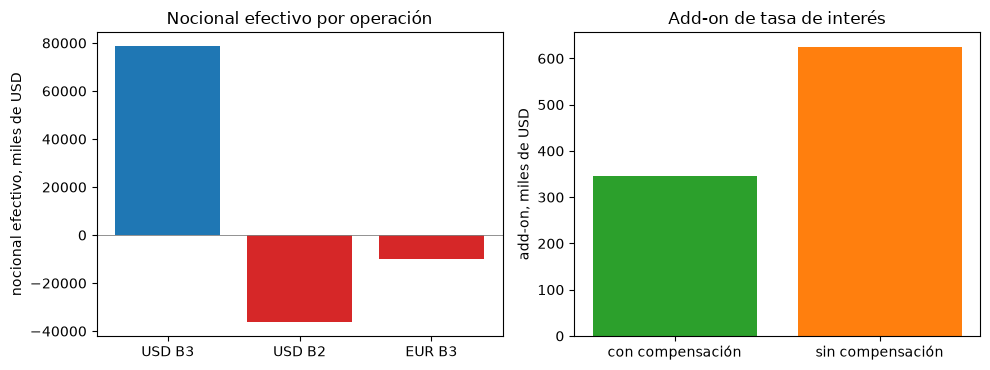

In [6]:
# Dibujar el nocional efectivo por operación (izquierda) y el add-on con y sin compensación (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
labels = [f"{row.hedging_set} {row.bucket}" for row in ir.trades]
effective = [row.effective_notional for row in ir.trades]
left.bar(labels, effective, color=["tab:blue" if v > 0 else "tab:red" for v in effective])
left.axhline(0, color="grey", lw=0.6)
left.set_ylabel("nocional efectivo, miles de USD")
left.set_title("Nocional efectivo por operación")
right.bar(["con compensación", "sin compensación"], [ir.addon, no_offset],
          color=["tab:green", "tab:orange"])
right.set_ylabel("add-on, miles de USD")
right.set_title("Add-on de tasa de interés")
fig.tight_layout()
plt.show()

A la izquierda, el pagador a 10 años y la swaption en EUR están en el tramo B3 con signo opuesto al receptor a 4 años en B2. Dentro del conjunto de cobertura en USD los dos tramos se compensan, porque la fórmula de CRE52.57 deja que un signo opuesto en un tramo vecino reduzca el total. A la derecha, la compensación baja el add-on casi a la mitad. La figura trata de una moneda y tres operaciones: muestra el mecanismo, no el tamaño que tendría la compensación en un libro con muchas operaciones en cada tramo, donde los términos de correlación de la fórmula pesarían más.

### Paso 4: el add-on de crédito (conjunto 2)

Las operaciones de crédito tienen también nocional efectivo $\delta \times N \times SD \times MF$, pero se agregan por entidad de referencia y calificación: el add-on de la entidad es $A_e = SF_e \times EN_e$ con el factor supervisor de su calificación (un nombre único AA, un nombre único BBB, un índice de grado de inversión) y una correlación $\rho_e$ con el factor sistemático (0,5 para un nombre único, 0,8 para un índice). El add-on de la clase de activo es (CRE52.61)

$$\text{AddOn}^{crédito} = \sqrt{\Big(\sum_e \rho_e A_e\Big)^2 + \sum_e (1 - \rho_e^2) A_e^2}$$

Los dos términos bajo la raíz son la parte sistemática y la idiosincrática; el BIS los imprime. `credit_addon_terms`, del motor, devuelve ambos y el add-on. La celda siguiente los calcula para el conjunto 2.

In [7]:
# Nocional efectivo por entidad de crédito, luego los términos sistemático e idiosincrático y el add-on del conjunto 2
ns2 = examples["cre99-netting-set-2"]
terms2 = [{v["name"]: v["value"] for v in tr["terms"]} for tr in ns2["trades"]]
entities = {}
for t in terms2:
    delta = LINEAR_DELTA[t["position"]]
    en = sa_ccr.credit_trade_effective_notional(delta, t["notional"], t["start_years"], t["end_years"])
    row = entities.setdefault(t["entity"], [t["rating"], t["reference_kind"] == "index", 0.0])
    row[2] += en
    side = "comprador de protección" if delta > 0 else "vendedor de protección"
    print(f"{t['entity']:10s} {t['rating']:4s} {side:24s} nocional efectivo {en:12.4f}")
credit_terms = sa_ccr.credit_addon_terms(
    [sa_ccr.CreditEntity(rating, is_index, en) for rating, is_index, en in entities.values()]
)
print("término sistemático (sum rho A)^2:", round(credit_terms.systematic, 4))
print("término idiosincrático sum (1 - rho^2) A^2:", round(credit_terms.idiosyncratic, 4))
print("add-on de crédito:", round(credit_terms.addon, 6))

Firm A     AA   comprador de protección  nocional efectivo   27858.4047
Firm B     BBB  vendedor de protección   nocional efectivo  -51836.3559
CDX.IG 5y  IG   comprador de protección  nocional efectivo   44239.8434
término sistemático (sum rho A)^2: 2252.635
término idiosincrático sum (1 - rho^2) A^2: 77344.0428
add-on de crédito: 282.128832


### Paso 5: el add-on de materias primas (conjunto 3)

Para materias primas los conjuntos de cobertura son energía, metales, agricultura y así sucesivamente; dentro de un conjunto, las operaciones del mismo tipo de materia prima se suman con su signo, y los tipos de un conjunto se agregan con la misma fórmula sistemática e idiosincrática, usando el factor y la correlación del tipo (0,18 y 0,4 para petróleo, gas, metales y agrícolas; la electricidad tiene su propia fila). El add-on de la clase es la suma sobre los conjuntos de cobertura. El nocional efectivo de una operación es $\delta \times \text{nocional ajustado} \times MF$. `commodity_trade_effective_notional` y `commodity_addon`, del motor, lo hacen. La celda siguiente calcula el conjunto 3.

In [8]:
# Nocional efectivo por tipo de materia prima, luego el add-on por conjunto de cobertura y en total del conjunto 3
ns3 = examples["cre99-netting-set-3"]
terms3 = [{v["name"]: v["value"] for v in tr["terms"]} for tr in ns3["trades"]]
sets3 = {}
POSITION = {"long": "larga", "short": "corta"}
for t in terms3:
    delta = LINEAR_DELTA[t["position"]]
    en = sa_ccr.commodity_trade_effective_notional(delta, t["adjusted_notional"], t["maturity_years"])
    key = "commodity-electricity" if t["commodity_type"] == "electricity" else OTHER
    sets3.setdefault(t["hedging_set"], {}).setdefault(t["commodity_type"], [key, 0.0])[1] += en
    side = POSITION[t["position"]]
    print(f"{t['hedging_set']:7s}{t['commodity_type']:10s}{side:6s} vencimiento {t['maturity_years']:5.2f}"
          f" nocional efectivo {en:12.4f}")
by_set = {}
for hs, types in sets3.items():
    by_set[hs] = [
        sa_ccr.CommodityEntity(sa_ccr.supervisory_parameter(k, "supervisory_factor").value,
                               sa_ccr.supervisory_parameter(k, "correlation").value, en)
        for k, en in types.values()
    ]
for hs, group in by_set.items():
    print(f"add-on del conjunto de cobertura {hs}:", round(sa_ccr.commodity_addon({hs: group}), 4))
commodity_total = sa_ccr.commodity_addon(by_set)
print("add-on de materias primas:", round(commodity_total, 4))

energy crude-oil larga  vencimiento  0.75 nocional efectivo    8660.2540
energy crude-oil corta  vencimiento  2.00 nocional efectivo  -20000.0000
metals silver    larga  vencimiento  5.00 nocional efectivo   10000.0000
add-on del conjunto de cobertura energy: 2041.1543
add-on del conjunto de cobertura metals: 1800.0
add-on de materias primas: 3841.1543


### Paso 6: costo de reemplazo, multiplicador y EAD de los conjuntos sin margen

Con los add-ons, el conjunto de neteo necesita su valor $V$ (la suma de los valores de mercado de sus operaciones) y la garantía $C$. Para un conjunto sin margen, $RC = \max(V - C, 0)$. El multiplicador es 1 cuando $V - C \ge 0$ y baja hacia el piso de 5% cuanto más sobregarantizado o más fuera del dinero está el conjunto: en el conjunto 2, $V = -20$ da 0,965. `replacement_cost`, `multiplier` y `netting_set_ead`, del motor, lo aplican. La celda siguiente calcula los conjuntos 1, 2 y 3, y el conjunto 4, que es los conjuntos 1 y 2 juntos: su add-on es la suma del add-on de tasa de interés del conjunto 1 y el add-on de crédito del conjunto 2, porque los add-ons se suman entre clases de activo, mientras que su valor y su RC netean los dos conjuntos.

In [9]:
# RC, multiplicador, PFE y EAD de los conjuntos 1 a 3, y el conjunto 4 como los conjuntos 1 y 2 juntos
v = {1: sum(t["market_value"] for t in terms1), 2: sum(t["market_value"] for t in terms2),
     3: sum(t["market_value"] for t in terms3)}
v[4] = v[1] + v[2]
addons = {
    1: sa_ccr.AddOnByClass(interest_rate=ir.addon),
    2: sa_ccr.AddOnByClass(credit=credit_terms.addon),
    3: sa_ccr.AddOnByClass(commodity=commodity_total),
    4: sa_ccr.AddOnByClass(interest_rate=ir.addon, credit=credit_terms.addon),
}
result = {n: sa_ccr.netting_set_ead(v[n], 0.0, addons[n]) for n in addons}

print(f"{'':6s}{'V':>6s}{'RC':>8s}{'AddOn':>10s}{'mult.':>8s}{'PFE':>10s}{'EAD':>10s}")
for n, r_ in result.items():
    print(f"conj. {n}{v[n]:6.0f}{r_.rc:8.2f}{r_.addon_aggregate:10.4f}{r_.multiplier:8.4f}{r_.pfe:10.4f}{r_.ead:10.4f}")
print("multiplicador del conjunto 2 desde las entradas de la fórmula:",
      round(sa_ccr.multiplier(-20.0, credit_terms.addon), 6))
print("conjunto 4: la RC netea los dos conjuntos (V = 40) y los add-ons se suman:",
      result[4].rc, round(result[4].addon_aggregate, 4))

           V      RC     AddOn   mult.       PFE       EAD
conj. 1    60   60.00  346.7644  1.0000  346.7644  569.4701
conj. 2   -20    0.00  282.1288  0.9652  272.3131  381.2383
conj. 3    20   20.00 3841.1543  1.0000 3841.1543 5405.6160
conj. 4    40   40.00  628.8932  1.0000  628.8932  936.4505
multiplicador del conjunto 2 desde las entradas de la fórmula: 0.965208
conjunto 4: la RC netea los dos conjuntos (V = 40) y los add-ons se suman: 40.0 628.8932


### Paso 7: un conjunto de neteo con margen (conjunto 5)

El conjunto 5 une las operaciones de tasa de interés del conjunto 1 con las de materias primas del conjunto 3 bajo un acuerdo de márgenes: $V = 80$, garantía $C = 200$, umbral $TH = 0$, monto mínimo de transferencia $MTA = 5$, monto independiente de garantía neto $NICA = 150$, y reposición de márgenes cada $N=5$ días hábiles en lugar de diaria. Cambian tres cosas:

- el MPoR es $F + N - 1$ con el piso $F = 10$ (CRE52.50 y CRE53.26, notebook 02): $10 + 5 - 1 = 14$ días hábiles;
- todo factor de vencimiento pasa a ser $1,5\sqrt{MPoR/250}$, igual para todas las operaciones;
- el costo de reemplazo es $RC = \max(V - C,\ TH + MTA - NICA,\ 0)$, así que un conjunto de neteo no puede tener un costo de reemplazo bajo los términos del margen.

La celda siguiente lo calcula todo.

In [10]:
# Conjunto 5: el MPoR desde el intervalo de reposición y los nocionales efectivos con márgenes
ns5 = examples["cre99-netting-set-5"]
ins5 = {i["name"]: i["value"] for i in ns5["inputs"]}
mpor = col.mpor_with_remargining(10, ins5["margin_frequency_business_days"])
mf5 = sa_ccr.maturity_factor(1.0, mpor)
print("MPoR = 10 + 5 - 1 =", mpor, "| factor de vencimiento:", round(mf5, 6))

terms5 = [{v_["name"]: v_["value"] for v_ in tr["terms"]} for tr in ns5["trades"]]
ir5, com5 = [], {}
for t in terms5:
    delta = delta_put if t.get("option_type", "none") != "none" else LINEAR_DELTA[t["position"]]
    if t["asset_class"] == "interest-rate":
        ir5.append(sa_ccr.IrTrade(t["currency"], t["start_years"], t["end_years"], t["notional"], delta))
    else:
        en = sa_ccr.commodity_trade_effective_notional(delta, t["adjusted_notional"], t["maturity_years"], mpor)
        com5.setdefault(t["hedging_set"], {}).setdefault(t["commodity_type"], [OTHER, 0.0])[1] += en
print("operaciones de tasa de interés:", len(ir5), "| conjuntos de cobertura de materias primas:", list(com5))

MPoR = 10 + 5 - 1 = 14 | factor de vencimiento: 0.354965
operaciones de tasa de interés: 3 | conjuntos de cobertura de materias primas: ['energy', 'metals']


El conjunto con márgenes se valora con los términos de margen que da el documento: $V = 80$, $C = 200$, $TH = 0$, $MTA = 5$ y $NICA = 150$. La celda siguiente calcula sus add-ons con el factor de vencimiento con márgenes, su costo de reemplazo, su multiplicador y su exposición al incumplimiento.

In [11]:
# Los add-ons con márgenes, el costo de reemplazo con los términos de margen, el multiplicador y la EAD del conjunto 5
addon_ir5 = sa_ccr.ir_addon(ir5, mpor).addon
by_set5 = {}
for hs, types in com5.items():
    by_set5[hs] = [
        sa_ccr.CommodityEntity(sa_ccr.supervisory_parameter(k, "supervisory_factor").value,
                               sa_ccr.supervisory_parameter(k, "correlation").value, en)
        for k, en in types.values()
    ]
addon_com5 = sa_ccr.commodity_addon(by_set5)
by_class5 = sa_ccr.AddOnByClass(interest_rate=addon_ir5, commodity=addon_com5)
res5 = sa_ccr.netting_set_ead(ins5["v"], ins5["c"], by_class5, True, ins5["th"], ins5["mta"], ins5["nica"])
result[5] = res5

print("términos de margen TH + MTA - NICA:", ins5["th"] + ins5["mta"] - ins5["nica"],
      "| V - C =", ins5["v"] - ins5["c"], "| RC =", res5.rc)
print("add-ons: tasa de interés, materias primas, agregado:",
      round(addon_ir5, 4), round(addon_com5, 4), round(res5.addon_aggregate, 4))
print("multiplicador:", round(res5.multiplier, 6), "| PFE:", round(res5.pfe, 4), "| EAD:", round(res5.ead, 4))

términos de margen TH + MTA - NICA: -145 | V - C = -120 | RC = 0.0
add-ons: tasa de interés, materias primas, agregado: 123.0891 1277.8732 1400.9624
multiplicador: 0.958123 | PFE: 1342.2947 | EAD: 1879.2126


La celda siguiente dibuja el add-on de cada conjunto de neteo por clase de activo, y su exposición al incumplimiento dividida en la parte de costo de reemplazo y la de exposición futura potencial.

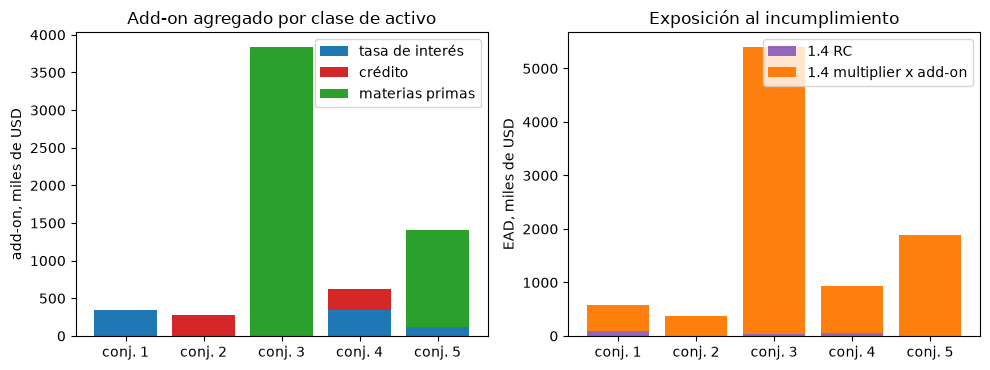

In [12]:
# Dibujar el add-on de cada conjunto por clase de activo (izquierda) y su EAD como 1,4 RC más 1,4 PFE (derecha)
parts = {1: (ir.addon, 0.0, 0.0), 2: (0.0, credit_terms.addon, 0.0), 3: (0.0, 0.0, commodity_total),
         4: (ir.addon, credit_terms.addon, 0.0), 5: (addon_ir5, 0.0, addon_com5)}
sets = list(result)
x = np.arange(len(sets))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
bottom = np.zeros(len(sets))
classes = (("tasa de interés", 0, "tab:blue"), ("crédito", 1, "tab:red"),
           ("materias primas", 2, "tab:green"))
for label, j, color in classes:
    heights = np.array([parts[n][j] for n in sets])
    left.bar(x, heights, bottom=bottom, color=color, label=label)
    bottom += heights
left.set_xticks(x, [f"conj. {n}" for n in sets])
left.set_ylabel("add-on, miles de USD")
left.set_title("Add-on agregado por clase de activo")
left.legend()
rc_part = np.array([1.4 * result[n].rc for n in sets])
pfe_part = np.array([1.4 * result[n].pfe for n in sets])
right.bar(x, rc_part, color="tab:purple", label="1.4 RC")
right.bar(x, pfe_part, bottom=rc_part, color="tab:orange", label="1.4 multiplier x add-on")
right.set_xticks(x, [f"conj. {n}" for n in sets])
right.set_ylabel("EAD, miles de USD")
right.set_title("Exposición al incumplimiento")
right.legend()
fig.tight_layout()
plt.show()

Las materias primas dominan la imagen: el conjunto 3 tiene un add-on de 3.841 frente a 347 de tasas de interés y 282 de crédito, por lo que su exposición al incumplimiento es más de diez veces la de los conjuntos 1 y 2. Los conjuntos 1 a 3 son casi todo exposición futura potencial, pues su costo de reemplazo es pequeño o cero, mientras que el conjunto 5, con un gran exceso de garantía, tiene costo de reemplazo cero y su exposición es solo el add-on, reducido por el factor de vencimiento con márgenes. La figura muestra los cinco ejemplos oficiales y nada más; los tamaños son la ilustración del marco, no un libro típico de banco.

### Paso 8: cada intermedio contra el valor impreso

El marco imprime cada intermedio redondeado (al entero más cercano, o a tres o cuatro decimales). La prueba es que nuestro número sin redondear, redondeado como lo redondea el marco, sea el impreso. La celda siguiente la hace para los cinco ejemplos, para cada salida que aparece en la lista `published`, tomando nuestro valor de los pasos anteriores.

In [13]:
# Comparar cada salida con el valor impreso tras el redondeo impreso, y las cinco EAD
FIELDS = ("rc", "addon_aggregate", "multiplier", "ead")
ours = {f"cre99-netting-set-{n}": {k: getattr(result[n], k) for k in FIELDS} for n in result}
hs1 = ir.hedging_sets
ours["cre99-netting-set-1"].update(addon_ir=ir.addon, swaption_delta=delta_put)
ours["cre99-netting-set-1"].update(en_usd=hs1[0].effective_notional, en_eur=hs1[1].effective_notional)
ours["cre99-netting-set-2"].update(term_1=credit_terms.systematic, term_2=credit_terms.idiosyncratic)
ours["cre99-netting-set-2"].update(addon_credit=credit_terms.addon)
energy = sa_ccr.commodity_addon({"energy": by_set["energy"]})
metals = sa_ccr.commodity_addon({"metals": by_set["metals"]})
ours["cre99-netting-set-3"].update(addon_commodity=commodity_total, addon_energy=energy, addon_metals=metals)
ours["cre99-netting-set-4"].update(addon_ir=ir.addon, addon_credit=credit_terms.addon)
ours["cre99-netting-set-5"].update(addon_ir=addon_ir5, addon_commodity=addon_com5, maturity_factor=mf5)

ROUNDING = {"nearest integer": 0, "3 decimal places": 3, "4 decimal places": 4}
checked = matched = 0
for ident, mine in ours.items():
    for p in examples[ident]["published"]:
        if p["name"] in mine:
            digits = ROUNDING.get(p["rounding"])
            shown = mine[p["name"]] if digits is None else round(mine[p["name"]], digits)
            matched += int(shown == p["value"])
            checked += 1
print("valores impresos verificados:", checked, "| iguales tras el redondeo impreso:", matched)
print(f"{'conj.':>6s}{'EAD, nuestra':>16s}{'EAD, impresa':>16s}")
for n in result:
    printed = {p["name"]: p["value"] for p in examples[f"cre99-netting-set-{n}"]["published"]}
    print(f"{n:6d}{result[n].ead:16.4f}{printed['ead']:16.0f}")

valores impresos verificados: 34 | iguales tras el redondeo impreso: 34
 conj.    EAD, nuestra    EAD, impresa
     1        569.4701             569
     2        381.2383             381
     3       5405.6160            5406
     4        936.4505             936
     5       1879.2126            1879


## Resultados

**Respuesta:** SA-CCR da a los cinco conjuntos de neteo oficiales una exposición al incumplimiento de 569,47, 381,24, 5.405,62, 936,45 y 1.879,21 (miles de USD), que se redondean a los 569, 381, 5.406, 936 y 1.879 que imprime el marco. La compensación entre tramos de vencimiento elimina 44,5% del add-on de tasa de interés del conjunto 1 (346,76 frente a 625,15 sin ella), el multiplicador del conjunto 2 es 0,9652 porque su valor es negativo, y el acuerdo de márgenes del conjunto 5 reduce todo factor de vencimiento a 0,3550.

- **Los parámetros.** La tabla de CRE52.72 tiene 43 filas, y cada parámetro viene con su párrafo, tabla y fecha de vigencia (2023-01-01), de modo que un número en pantalla puede mostrar de dónde viene.
- **Tasas de interés (conjunto 1).** El pagador a 10 años tiene duración 7,869 y nocional efectivo +78.694; el receptor a 4 años tiene duración 3,625 y cae en el tramo B2 con -36.254; la swaption en EUR tiene delta -0,2694, una put comprada. El conjunto de cobertura en USD compensa los dos tramos hasta un nocional efectivo de 59.270 y un add-on de 296,35; con el conjunto en EUR el add-on de tasa de interés es 346,76.
- **Crédito (conjunto 2).** El término sistemático es 2.252,6 y el idiosincrático 77.344,0; el add-on es 282,13.
- **Materias primas (conjunto 3).** El conjunto de energía da 2.041,15 y el de metales 1.800,00; el add-on de la clase es 3.841,15.
- **Agregación (conjunto 4).** El conjunto 4 es los conjuntos 1 y 2 juntos. Su add-on agregado, 628,89, es la suma 346,76 + 282,13, porque los add-ons se suman entre clases de activo, mientras que su costo de reemplazo, 40, netea los valores 60 y -20. La EAD es 936,45.
- **Márgenes (conjunto 5).** El MPoR es $10 + 5 - 1 = 14$ días hábiles, la entrada del documento. El costo de reemplazo es $\max(-120, -145, 0) = 0$. El multiplicador es 0,9581 y la EAD 1.879,21.
- **Contra el marco.** De los 34 intermedios impresos, los 34 coinciden tras el redondeo impreso.

Lo que el motor no implementa de SA-CCR está declarado en su documentación: el desplazamiento de strike y precio para tasas negativas (CRE52.40), la vega de opciones de FX y de materias primas, las operaciones de base y de volatilidad, y las reglas de signo de las operaciones de FX más allá de un nocional efectivo con signo que aporta quien llama. Los cinco ejemplos usan solo operaciones de tasa de interés, crédito y materias primas, así que no ejercitan los add-ons de FX y de renta variable, que el motor ofrece como `fx_addon` y `equity_addon`.

## Resumen

- $EAD = 1.4\,(RC + \text{multiplicador} \times \text{AddOn})$; el add-on es la suma sobre cinco clases de activo, cada una construida con nocionales efectivos $\delta \times N \times SD \times MF$.
- Las operaciones de tasa de interés se compensan entre tres tramos de vencimiento, las de crédito y materias primas entre entidades con una fórmula sistemática más idiosincrática, y los add-ons se suman entre clases.
- Un acuerdo de márgenes cambia tres cosas: el MPoR $F + N - 1$, el factor de vencimiento $1.5\sqrt{MPoR/250}$ y el costo de reemplazo $\max(V - C, TH + MTA - NICA, 0)$.
- Los cinco ejemplos de CRE99 se calculan desde sus operaciones: 34 de 34 intermedios impresos coinciden tras el redondeo impreso.

**Qué probar después.** Quita la compensación (`offset=False`) en el conjunto 5 y mira cuánto crece el add-on de tasa de interés; cambia la swaption a una put vendida y mira cómo el conjunto de cobertura en EUR cambia de signo. Luego sigue con el notebook 05.

## Referencias

- BCBS, Basel Framework, CRE52 Standardised approach to counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/52/inforce/2023-01-01/published/2020-06-05
- BCBS, Basel Framework, CRE99 Illustrative examples of the standardised approach to counterparty credit risk (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/99/inforce/2023-01-01/published/2020-03-27
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605